# Ensemble Learning for Next-Day Temperature in Gampaha, Sri Lanka
**Module:** CM4371 Machine Learning & Pattern Recognition  **Student:** A.L.k.H Ambegoda 224010J

 **AI disclosure:** The code in this notebook, the Streamlit dashboard App.py and the README were **generated with Claude (Anthropic)**.

## Project idea
Can an ensemble of models forecast tomorrow's mean temperature in Gampaha better than the obvious guess "tomorrow will be like today"?
I compare the three ensemble families from the lecture, plus hybrids, on 11 years of daily Sri Lankan weather.

| Family | Idea | Models used |
|---|---|---|
| **Bagging** | Train many models on random resamples, then average. Reduces *variance*. | Random Forest, Bagged Trees |
| **Boosting** | Train models one after another; each fixes the previous one's errors. Reduces *bias*. | Gradient Boosting, XGBoost, LightGBM, CatBoost |
| **Stacking** | Different model types make predictions; a meta-model learns how to weigh them. | RF + XGBoost + CatBoost + ANN, combined by Ridge |
| **Hybrid** | Combine a statistical time-series model with a machine-learning model. | ARIMA + Random Forest on the residuals, RF + ANN average |

**Data:** daily weather for Gampaha (7.09 N, 79.99 E), 2015-2025, from the free Open-Meteo Historical Weather API (ERA5 reanalysis). Weather data by [Open-Meteo.com](https://open-meteo.com/) (CC BY 4.0).

**Evaluation:** time-based split. Train on 2015-2023, test on 2024-2025. A random split would let the model "see the future", so it is not used.

## 1. Setup

In [ ]:
%pip install -q catboost lightgbm xgboost statsmodels

In [ ]:
import os, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from matplotlib.patches import Patch

from sklearn.base import clone
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor,
                              GradientBoostingRegressor, StackingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# Names used everywhere (the dashboard reads the same names)
PERSIST = "Persistence (today = tomorrow)"
ARIMA_ALONE = "ARIMA(2,0,1) alone"
HYB_ARIMA = "RF + ARIMA (residual hybrid)"
HYB_ANN = "RF + ANN (average)"
STACK = "Stacking (RF+XGB+CatBoost+ANN -> Ridge)"

FAMILY_COLORS = {"Baseline": "#9aa0a6", "Bagging": "#2e7d32", "Boosting": "#e65100",
                 "Neural net": "#6a1b9a", "Hybrid": "#0277bd", "Stacking": "#c62828"}

## 2. Data: daily weather in Gampaha
The first run downloads the data from Open-Meteo and saves it as `gampaha_weather.csv`. Later runs reuse that file.
Variables: mean/max/min temperature (deg C), precipitation (mm), max wind speed (km/h) and shortwave radiation (MJ/m2).

In [ ]:
LAT, LON = 7.0917, 79.9999          # Gampaha
START, END = "2015-01-01", "2025-12-31"
CSV = "gampaha_weather.csv"
DAILY = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
         "precipitation_sum", "wind_speed_10m_max", "shortwave_radiation_sum"]

if os.path.exists(CSV):
    raw = pd.read_csv(CSV, parse_dates=["date"])
    print("Loaded cached", CSV)
else:
    r = requests.get("https://archive-api.open-meteo.com/v1/archive",
                     params=dict(latitude=LAT, longitude=LON, start_date=START, end_date=END,
                                 daily=",".join(DAILY), timezone="Asia/Colombo"), timeout=120)
    r.raise_for_status()
    raw = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
    raw["date"] = pd.to_datetime(raw["date"])
    raw.to_csv(CSV, index=False)
    print("Downloaded and saved", CSV)

df = (raw.rename(columns={"temperature_2m_mean": "tmean", "temperature_2m_max": "tmax",
                          "temperature_2m_min": "tmin", "precipitation_sum": "rain",
                          "wind_speed_10m_max": "wind", "shortwave_radiation_sum": "rad"})
         .set_index("date").sort_index().asfreq("D").interpolate(limit=3))
print(df.shape, df.index.min().date(), "->", df.index.max().date())
print("Missing values:", int(df.isna().sum().sum()))
df.describe().round(2)

Downloaded and saved gampaha_weather.csv
(4018, 6) 2015-01-01 -> 2025-12-31
Missing values: 0


,tmean,tmax,tmin,rain,wind,rad
count,4018.00,4018.00,4018.00,4018.00,4018.00,4018.00
mean,26.56,30.35,23.75,8.07,14.98,18.32
std,0.99,1.82,1.19,11.92,3.94,4.13
min,23.20,23.90,18.10,0.00,4.70,2.24
25%,25.90,29.10,23.00,1.20,12.10,15.80
50%,26.50,30.10,23.90,4.10,15.00,18.95
75%,27.20,31.40,24.60,11.20,17.70,21.47
max,30.20,37.40,27.30,310.90,37.40,26.56


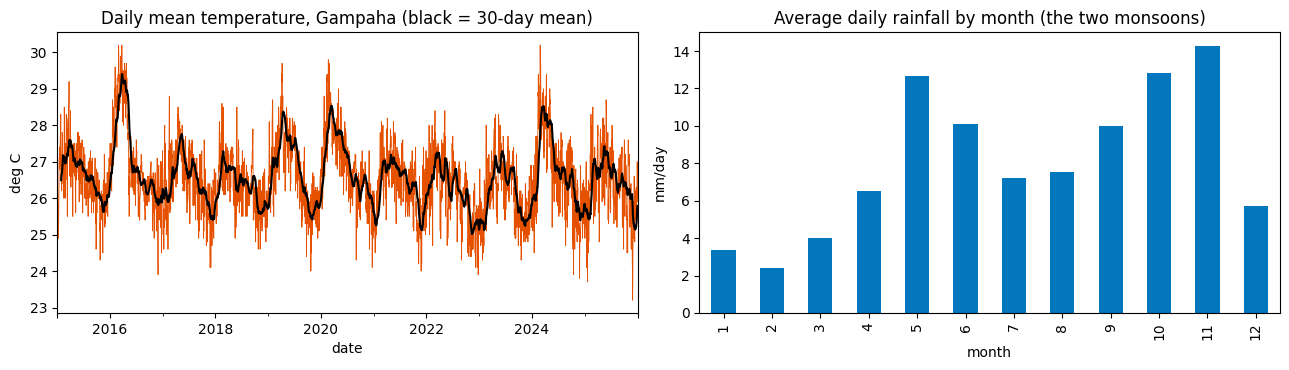

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
df["tmean"].plot(ax=ax[0], lw=0.6, color="#e65100")
df["tmean"].rolling(30).mean().plot(ax=ax[0], lw=1.5, color="black")
ax[0].set_title("Daily mean temperature, Gampaha (black = 30-day mean)"); ax[0].set_ylabel("deg C")
df.groupby(df.index.month)["rain"].mean().plot.bar(ax=ax[1], color="#0277bd")
ax[1].set_title("Average daily rainfall by month (the two monsoons)"); ax[1].set_xlabel("month"); ax[1].set_ylabel("mm/day")
plt.tight_layout(); plt.show()

**What to notice:** Gampaha is warm all year, and temperature varies only a few degrees, so the series is smooth and strongly tied to yesterday's value. That makes "tomorrow = today" a tough baseline to beat. Rainfall is seasonal (Southwest monsoon around May-June, Northeast monsoon around Oct-Nov).

## 3. Features and target
The target is **tomorrow's mean temperature**. Each row describes "today" using only information available today:
lagged values (today, 1, 2, 3 and 7 days ago) of every variable, rolling averages, and the day of the year encoded as sin/cos so that 31 Dec and 1 Jan are close together.

In [ ]:
base_vars = ["tmean", "tmax", "tmin", "rain", "wind", "rad"]
feat = pd.DataFrame(index=df.index)
for v in base_vars:
    for lag in [0, 1, 2, 3, 7]:
        feat[f"{v}_lag{lag}"] = df[v].shift(lag)
feat["tmean_roll7"] = df["tmean"].rolling(7).mean()
feat["tmean_roll30"] = df["tmean"].rolling(30).mean()
feat["rain_roll7"] = df["rain"].rolling(7).sum()
feat["rain_roll30"] = df["rain"].rolling(30).sum()
doy = df.index.dayofyear
feat["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
feat["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
feat["month"] = df.index.month
feat["target"] = df["tmean"].shift(-1)          # tomorrow's mean temperature
print(feat.shape)

(4018, 38)


## 4. ARIMA component (for the hybrid model)
ARIMA is a classic statistical time-series model. It captures the *linear* day-to-day memory in the temperature series.
I fit it **only on the training period**, then use it to make one-step-ahead forecasts for every day (the parameters stay fixed, so the test period is not leaked).
Later, a Random Forest will learn what ARIMA gets wrong.

In [ ]:
TEST_START = "2024-01-01"
tmean_train = df.loc[df.index < TEST_START, "tmean"]

arima_res = ARIMA(tmean_train, order=(2, 0, 1)).fit()
arima_full = arima_res.apply(df["tmean"])        # same parameters, run over the whole series
one_step = arima_full.fittedvalues               # prediction of day t made from days before t
feat["arima_pred"] = one_step.shift(-1)          # ARIMA's forecast of TOMORROW made from today's info
print(arima_res.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         26.5282      0.181    146.400      0.000      26.173      26.883
ar.L1          1.5726      0.021     74.365      0.000       1.531       1.614
ar.L2         -0.5772      0.020    -28.323      0.000      -0.617      -0.537
ma.L1         -0.9021      0.013    -69.327      0.000      -0.928      -0.877
sigma2         0.2445      0.006     43.825      0.000       0.234       0.255


## 5. Time-based train/test split and baselines

In [ ]:
data = feat.dropna().copy()
FEATURES = [c for c in data.columns if c not in ("target", "arima_pred")]
train = data[data.index < TEST_START]
test = data[data.index >= TEST_START]
X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test : {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")
print(f"{len(FEATURES)} input features")

results, preds, fitted = [], {}, {}

def evaluate(name, family, y_pred, fit_s=0.0):
    preds[name] = np.asarray(y_pred, dtype=float)
    results.append(dict(model=name, family=family,
                        MAE=mean_absolute_error(y_test, y_pred),
                        RMSE=float(np.sqrt(mean_squared_error(y_test, y_pred))),
                        R2=r2_score(y_test, y_pred), fit_seconds=round(fit_s, 2)))

# Baselines every model must beat
evaluate(PERSIST, "Baseline", test["tmean_lag0"])
evaluate(ARIMA_ALONE, "Baseline", test["arima_pred"])
pd.DataFrame(results).round(3)

Train: 3258 days (2015-01-30 to 2023-12-31)
Test : 730 days (2024-01-01 to 2025-12-30)
37 input features


,model,family,MAE,RMSE,R2,fit_seconds
0,Persistence (today = tomorrow),Baseline,0.508,0.657,0.619,0.0
1,"ARIMA(2,0,1) alone",Baseline,0.475,0.607,0.676,0.0


## 6. Bagging, boosting and a neural network
Settings are moderate and fixed, so the comparison is fair and everything runs in a couple of minutes.
The ANN is a small multi-layer perceptron; it needs scaled inputs, so it sits inside a pipeline with `StandardScaler`.

In [ ]:
base_models = {
    "Random Forest": ("Bagging", RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED)),
    "Bagged Trees": ("Bagging", BaggingRegressor(
        n_estimators=200, max_samples=0.8, n_jobs=-1, random_state=SEED)),
    "Gradient Boosting": ("Boosting", GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED)),
    "XGBoost": ("Boosting", XGBRegressor(
        n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8,
        colsample_bytree=0.8, n_jobs=-1, random_state=SEED)),
    "LightGBM": ("Boosting", LGBMRegressor(
        n_estimators=400, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, random_state=SEED, verbose=-1)),
    "CatBoost": ("Boosting", CatBoostRegressor(
        iterations=500, learning_rate=0.05, depth=5, random_seed=SEED, verbose=0)),
    "ANN (MLP)": ("Neural net", make_pipeline(StandardScaler(), MLPRegressor(
        hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
        max_iter=500, random_state=SEED))),
}

for name, (family, model) in base_models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    evaluate(name, family, model.predict(X_test), time.time() - t0)
    fitted[name] = model
    print(f"{name:18s} done in {time.time() - t0:5.1f}s")

Random Forest      done in  26.1s
Bagged Trees       done in  18.6s
Gradient Boosting  done in   7.8s
XGBoost            done in   1.0s
LightGBM           done in   0.7s
CatBoost           done in   2.4s
ANN (MLP)          done in  18.1s


## 7. Hybrid models
1. **RF + ARIMA (residual hybrid).** ARIMA makes the first forecast. A Random Forest is then trained to predict ARIMA's *error* from the weather features. Final forecast = ARIMA forecast + RF correction.
2. **RF + ANN (average).** A simple blend of the bagging model and the neural network.

In [ ]:
t0 = time.time()
resid_train = train["target"] - train["arima_pred"]
rf_resid = clone(base_models["Random Forest"][1]).fit(X_train, resid_train)
evaluate(HYB_ARIMA, "Hybrid", test["arima_pred"] + rf_resid.predict(X_test), time.time() - t0)

evaluate(HYB_ANN, "Hybrid", (preds["Random Forest"] + preds["ANN (MLP)"]) / 2)
pd.DataFrame(results).tail(2).round(3)

,model,family,MAE,RMSE,R2,fit_seconds
9,RF + ARIMA (residual hybrid),Hybrid,0.465,0.590,0.693,14.52
10,RF + ANN (average),Hybrid,0.543,0.808,0.424,0.00


## 8. Stacking
Four *different* base models (a bagging model, two boosting models, a neural network) make predictions. A Ridge regression (the "meta-model") learns how much to trust each one.
The meta-model is trained on out-of-fold predictions (5 folds) so it does not just reward models that memorised the training data.

In [ ]:
t0 = time.time()
stack = StackingRegressor(
    estimators=[("rf", clone(base_models["Random Forest"][1])),
                ("xgb", clone(base_models["XGBoost"][1])),
                ("cat", clone(base_models["CatBoost"][1])),
                ("ann", clone(base_models["ANN (MLP)"][1]))],
    final_estimator=Ridge(alpha=1.0), cv=5)
stack.fit(X_train, y_train)
evaluate(STACK, "Stacking", stack.predict(X_test), time.time() - t0)
fitted[STACK] = stack

weights = {k: round(float(v), 3) for k, v in zip(["Random Forest", "XGBoost", "CatBoost", "ANN (MLP)"], stack.final_estimator_.coef_)}
print("Meta-model weights:", weights, "| intercept:", round(float(stack.final_estimator_.intercept_), 3))

Meta-model weights: {'Random Forest': 0.435, 'XGBoost': 0.321, 'CatBoost': 0.269, 'ANN (MLP)': 0.028} | intercept: -1.423


In [ ]:
ann = fitted["ANN (MLP)"]
from sklearn.metrics import mean_squared_error
print("ANN train RMSE:", mean_squared_error(y_train, ann.predict(X_train)) ** 0.5)
print("ANN test  RMSE:", mean_squared_error(y_test, ann.predict(X_test)) ** 0.5)
print("Mean error on test (bias):", (y_test - ann.predict(X_test)).mean())

ANN train RMSE: 0.43168679495261664
ANN test  RMSE: 1.230982625379389
Mean error on test (bias): -0.02783655228357111


## 9. Results

In [ ]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results_df.round(3)

,model,family,MAE,RMSE,R2,fit_seconds
0,RF + ARIMA (residual hybrid),Hybrid,0.465,0.590,0.693,14.52
1,Gradient Boosting,Boosting,0.471,0.597,0.685,7.81
2,Bagged Trees,Bagging,0.473,0.598,0.684,18.60
3,Random Forest,Bagging,0.472,0.599,0.684,26.13
4,Stacking (RF+XGB+CatBoost+ANN -> Ridge),Stacking,0.471,0.600,0.683,112.29
5,CatBoost,Boosting,0.475,0.603,0.680,2.36
6,LightGBM,Boosting,0.474,0.603,0.680,0.74
7,XGBoost,Boosting,0.476,0.603,0.679,0.98
8,"ARIMA(2,0,1) alone",Baseline,0.475,0.607,0.676,0.00
9,Persistence (today = tomorrow),Baseline,0.508,0.657,0.619,0.00


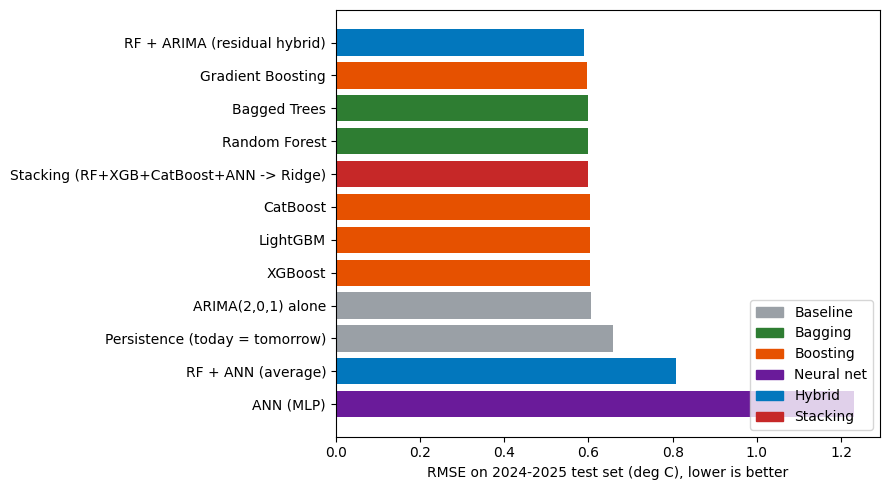

In [ ]:
plot_df = results_df.sort_values("RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["model"], plot_df["RMSE"], color=[FAMILY_COLORS[f] for f in plot_df["family"]])
ax.set_xlabel("RMSE on 2024-2025 test set (deg C), lower is better")
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAMILY_COLORS.items()], loc="lower right")
plt.tight_layout(); plt.show()

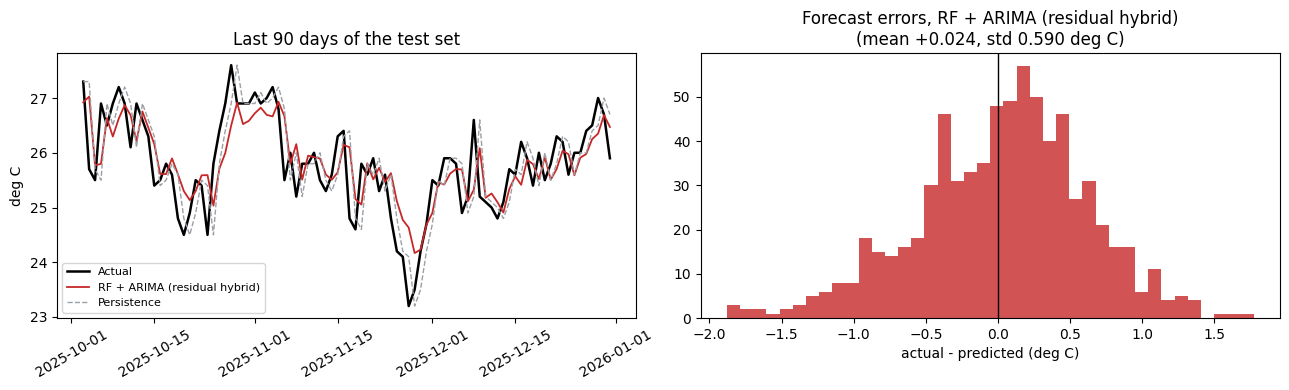

In [ ]:
best = results_df.loc[0, "model"]
best_pred = preds[best]
last = slice(-90, None)
idx = (test.index + pd.Timedelta(days=1))[last]          # the day being forecast

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(idx, y_test.values[last], color="black", lw=1.8, label="Actual")
ax[0].plot(idx, best_pred[last], color="#c62828", lw=1.3, label=best)
ax[0].plot(idx, preds[PERSIST][last], color="#9aa0a6", lw=1, ls="--", label="Persistence")
ax[0].set_title("Last 90 days of the test set"); ax[0].set_ylabel("deg C"); ax[0].legend(fontsize=8)
ax[0].tick_params(axis="x", rotation=30)

resid = y_test.values - best_pred
ax[1].hist(resid, bins=40, color="#c62828", alpha=0.8)
ax[1].axvline(0, color="black", lw=1)
ax[1].set_title(f"Forecast errors, {best}\n(mean {resid.mean():+.3f}, std {resid.std():.3f} deg C)")
ax[1].set_xlabel("actual - predicted (deg C)")
plt.tight_layout(); plt.show()

### Error by month (does difficulty change with the season?)

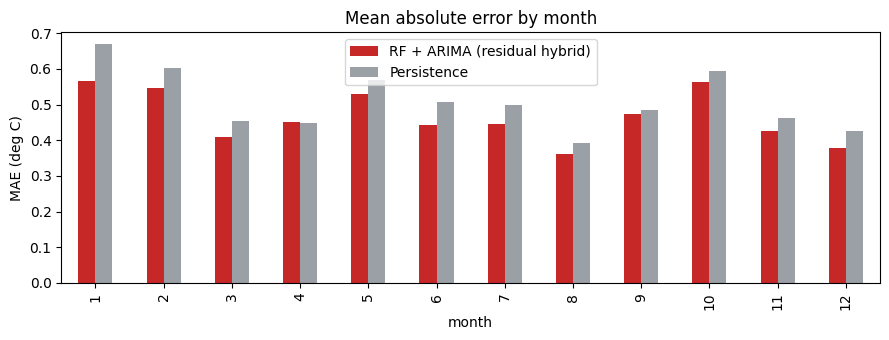

In [ ]:
err = pd.DataFrame({"month": (test.index + pd.Timedelta(days=1)).month,
                    best: np.abs(y_test.values - best_pred),
                    "Persistence": np.abs(y_test.values - preds[PERSIST])})
err.groupby("month").mean().plot.bar(figsize=(9, 3.5), color=["#c62828", "#9aa0a6"])
plt.ylabel("MAE (deg C)"); plt.title("Mean absolute error by month"); plt.tight_layout(); plt.show()

## 10. Which features matter?
Tree models report how much each feature helped. I also use **permutation importance** on the test set: shuffle one feature and see how much the error grows.

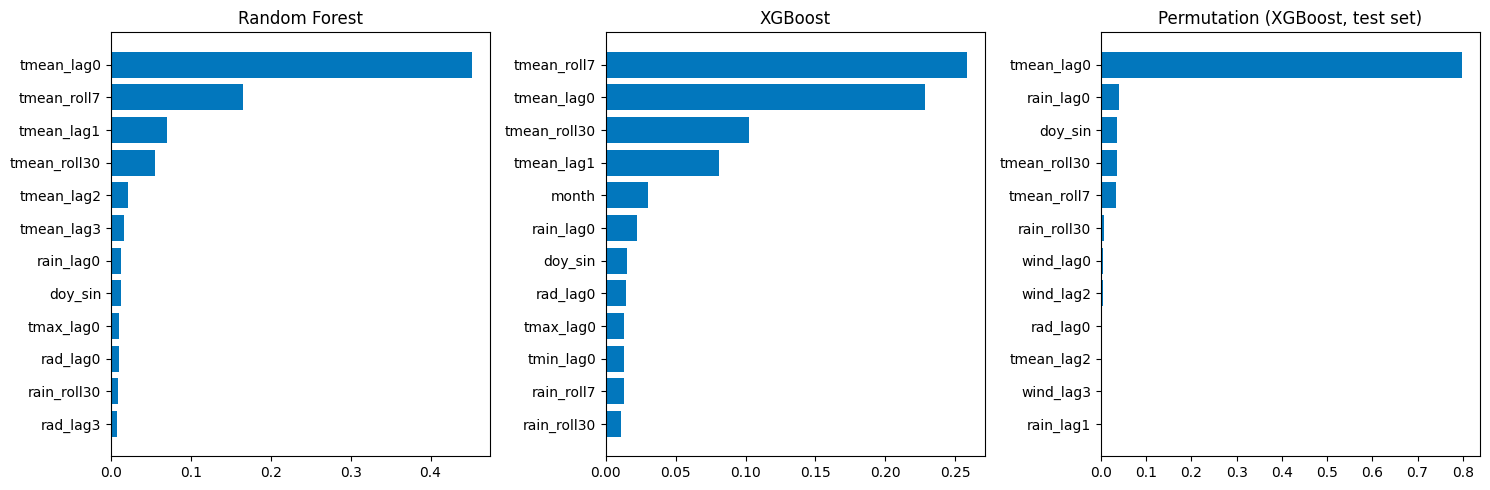

In [ ]:
imp = pd.DataFrame({"feature": FEATURES})
for name in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]:
    v = np.asarray(fitted[name].feature_importances_, dtype=float)
    imp[name] = v / v.sum()

perm = permutation_importance(fitted["XGBoost"], X_test, y_test, n_repeats=5, random_state=SEED,
                              scoring="neg_root_mean_squared_error")
pv = np.clip(perm.importances_mean, 0, None)
imp["Permutation (XGBoost, test set)"] = pv / pv.sum() if pv.sum() > 0 else pv

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, col in zip(ax, ["Random Forest", "XGBoost", "Permutation (XGBoost, test set)"]):
    top = imp.nlargest(12, col).iloc[::-1]
    a.barh(top["feature"], top[col], color="#0277bd"); a.set_title(col)
plt.tight_layout(); plt.show()

## 11. Automatic summary of the numbers
This cell reads the results table and writes the key comparisons, so the numbers in your report always match the notebook.

In [ ]:
r = results_df.set_index("model")
def rmse(m): return r.loc[m, "RMSE"]
fam = lambda f: r[r.family == f]["RMSE"]

print(f"1. Best model: {best}  (RMSE {rmse(best):.3f} C, MAE {r.loc[best, 'MAE']:.3f} C, R2 {r.loc[best, 'R2']:.3f})")
print(f"2. Versus 'tomorrow = today': {(1 - rmse(best) / rmse(PERSIST)) * 100:+.1f}% lower RMSE "
      f"({rmse(PERSIST):.3f} -> {rmse(best):.3f})")
bag, boo = fam("Bagging"), fam("Boosting")
print(f"3. Best bagging  : {bag.idxmin()} ({bag.min():.3f})   |   Best boosting: {boo.idxmin()} ({boo.min():.3f})")
print(f"   -> {'Boosting' if boo.min() < bag.min() else 'Bagging'} wins by {abs(boo.min() - bag.min()) / max(boo.min(), bag.min()) * 100:.1f}%")
print(f"4. ARIMA alone {rmse(ARIMA_ALONE):.3f}  ->  RF + ARIMA hybrid {rmse(HYB_ARIMA):.3f}  "
      f"({(1 - rmse(HYB_ARIMA) / rmse(ARIMA_ALONE)) * 100:+.1f}%)")
bases = r[r.family.isin(["Bagging", "Boosting", "Neural net"])]["RMSE"]
print(f"5. Stacking {rmse(STACK):.3f} vs best single model {bases.idxmin()} {bases.min():.3f}  "
      f"({(1 - rmse(STACK) / bases.min()) * 100:+.1f}%)")
print(f"6. Meta-model weights: {weights}")
print(f"7. RF + ANN average {rmse(HYB_ANN):.3f} vs RF {rmse('Random Forest'):.3f} vs ANN {rmse('ANN (MLP)'):.3f}")
print("8. Top features (Random Forest):", ", ".join(imp.nlargest(3, "Random Forest")["feature"]))
print("   Top features (permutation):  ", ", ".join(imp.nlargest(3, "Permutation (XGBoost, test set)")["feature"]))

1. Best model: RF + ARIMA (residual hybrid)  (RMSE 0.590 C, MAE 0.465 C, R2 0.693)
2. Versus 'tomorrow = today': +10.2% lower RMSE (0.657 -> 0.590)
3. Best bagging  : Bagged Trees (0.598)   |   Best boosting: Gradient Boosting (0.597)
   -> Boosting wins by 0.1%
4. ARIMA alone 0.607  ->  RF + ARIMA hybrid 0.590  (+2.7%)
5. Stacking 0.600 vs best single model Gradient Boosting 0.597  (-0.4%)
6. Meta-model weights: {'Random Forest': 0.435, 'XGBoost': 0.321, 'CatBoost': 0.269, 'ANN (MLP)': 0.028}
7. RF + ANN average 0.808 vs RF 0.599 vs ANN 1.231
8. Top features (Random Forest): tmean_lag0, tmean_roll7, tmean_lag1
   Top features (permutation):   tmean_lag0, rain_lag0, doy_sin


## 12. Interpretation: why did the models behave this way?

**Strong baseline** "Tomorrow = today" gives RMSE 0.657 °C. Daily temperature in a tropical lowland changes slowly, so this is a hard baseline. The best model (RF + ARIMA hybrid, 0.590 °C) is 10.2% better. Most of that gain comes from ARIMA alone (0.607 °C, 7.6% better than persistence), which smooths day-to-day noise and pulls forecasts back towards the seasonal level. The machine-learning layer added a further 2.7%.

**Bagging vs boosting is a tie**, Bagged Trees (0.598), Random Forest (0.599) and Gradient Boosting (0.597) differ by about 0.002 °C. With only two test years (730 days), this is within noise, so I cannot claim either family is better. The likely reason is that the relationship is simple: tomorrow's temperature is mostly today's temperature plus a seasonal shift. Bagging reduces variance by averaging many trees. Boosting reduces bias by fitting errors step by step, but there is little hidden structure left for it to find. Random Forest did not beat plain bagged trees here, probably because with highly correlated lag features, random feature sampling adds little.

**ANN (MLP)**ANN (MLP) overfit (train RMSE 0.432 vs test RMSE 1.231). The test error is nearly three times the training error, so the network memorised the training period instead of learning a pattern that carries over to 2024-25. The mean test error was close to zero (-0.03 °C), so it is not a warm or cool shift; the errors are large but scattered both ways. With only about 3,200 daily rows, 37 correlated features and an untuned network, this is expected: a neural network has far more freedom to fit noise than a tree ensemble does with the same data. It is a weakness of this configuration, not evidence that neural networks cannot forecast temperature. Because it was so much worse, the RF + ANN average (0.808) was worse than RF alone: averaging only helps when both models are reasonably accurate. Stacking handled this sensibly by giving the ANN almost no weight (0.028).

**RF + ARIMA** hybrid (best, 0.590). ARIMA captures the linear memory in the temperature series, and the Random Forest then corrects its errors using other variables. The hybrid improved on ARIMA alone by 2.7% (0.607 to 0.590) and on the best single model, Gradient Boosting, by about 1.2%. The permutation importance ranks rain_lag0 second, which supports the idea that rainfall carries information beyond temperature history (rain cools the next day). The margin over the other models is small, so I describe it as the best result in this test, not a proven winner.

**Stacking** did not help (0.600 vs 0.597 for Gradient Boosting). The meta-model spread its weight across the three tree models (RF 0.435, XGBoost 0.321, CatBoost 0.269) and almost ignored the ANN (0.028). The tree models see the same features and make similar errors, so combining them adds little. Stacking also costs more time, since every base model is trained five times for cross-validation. (Gradient Boosting was not one of the stack's base models.)

**Features** tmean_lag0 is the top feature in both measures, followed by tmean_roll7 and tmean_lag1 for Random Forest, and rain_lag0 and doy_sin for permutation importance. In other words, temperature is mostly yesterday's temperature, plus the season and recent rain.

**Limitations** One location; ERA5 reanalysis is a model estimate, not station data; only two test years, so differences of a few thousandths of a degree are not meaningful; hyperparameters were fixed rather than tuned (the ANN especially).

My Conclution: The RF + ARIMA hybrid gave the best result (RMSE 0.590 deg C) 10.2% better than "tomorrow = today". Bagging and boosting were within 0.002 deg C of each other, so non of it was a clear winer, which I believe is due to the simple, largely autoregressive, nature of temperature. Stacking underperformed relative to the best single model because 1.The base models tend to produce similar errors 2.The ANN was much weaker than the trees, so averaging it with RF did not improve the result. The main limitation is the brief two-year test period, making small differences less meaningful.

## 13. Save everything the dashboard needs

In [ ]:
os.makedirs("artifacts", exist_ok=True)

bundle = {
    "models": fitted,                         # fitted models that predict directly from the feature table
    "hybrid_residual_model": rf_resid,        # RF trained on ARIMA residuals
    "feature_cols": FEATURES,
    "meta": {"PERSIST": PERSIST, "ARIMA_ALONE": ARIMA_ALONE, "HYB_ARIMA": HYB_ARIMA, "HYB_ANN": HYB_ANN,
             "STACK": STACK, "location": "Gampaha, Sri Lanka", "lat": LAT, "lon": LON,
             "train_end": str(train.index.max().date()), "test_start": TEST_START,
             "meta_weights": {k: float(v) for k, v in weights.items()}},
}
joblib.dump(bundle, "artifacts/models.joblib", compress=3)

data.assign(split=np.where(data.index < TEST_START, "train", "test")).rename_axis("date").to_csv("artifacts/features.csv")
pd.DataFrame({"date": test.index + pd.Timedelta(days=1), "actual": y_test.values,
              **{k: v for k, v in preds.items()}}).to_csv("artifacts/test_predictions.csv", index=False)
results_df.to_csv("artifacts/metrics.csv", index=False)
imp.to_csv("artifacts/importances.csv", index=False)

# requirements.txt with the exact versions used here, so the pickled models load on the web server
from importlib.metadata import version, PackageNotFoundError
lines = []
for p in ["streamlit", "pandas", "numpy", "plotly", "scikit-learn", "joblib", "xgboost", "lightgbm", "catboost"]:
    try:
        lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError:
        lines.append(p)
open("artifacts/requirements.txt", "w").write("\n".join(lines) + "\n")

print("Saved:", sorted(os.listdir("artifacts")))
print(f"models.joblib size: {os.path.getsize('artifacts/models.joblib') / 1e6:.1f} MB")

Saved: ['features.csv', 'importances.csv', 'metrics.csv', 'models.joblib', 'requirements.txt', 'test_predictions.csv']
models.joblib size: 32.0 MB


In [ ]:
# Colab: download the artifacts folder as a zip (does nothing on your own computer)
import shutil
shutil.make_archive("artifacts", "zip", "artifacts")
try:
    from google.colab import files
    files.download("artifacts.zip")
except ImportError:
    print("Not on Colab: files are in the ./artifacts folder (and artifacts.zip).")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
**AI disclosure (repeated):** code in this notebook was generated with Claude (Anthropic). Weather data: Open-Meteo.com (CC BY 4.0).